In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Load clean data
clients = pd.read_csv("../data/processed/clients_clean.csv", parse_dates=["date_of_birth"])
props = pd.read_csv("../data/processed/props_clean.csv", parse_dates=["transaction_date"])

In [3]:
# shape and column type
print(clients.shape, props.shape)
print(clients.dtypes)
print(props.dtypes)

(2000, 13) (10000, 9)
client_id                      object
client_type                    object
first_name                     object
last_name                      object
date_of_birth          datetime64[ns]
gender                         object
country                        object
region                         object
acquisition_purpose            object
satisfaction_score              int64
loan_applied                   object
referral_channel               object
is_company                      int64
dtype: object
listing_id                   int64
tower_number                 int64
transaction_date    datetime64[ns]
unit_category               object
unit_number                  int64
floor_area_sqft            float64
sale_price                 float64
listing_status              object
client_ref                  object
dtype: object


In [4]:
# count listings and sold vs available
monthly = props.groupby(["transaction_date","listing_status"]).size().unstack(fill_value=0)
monthly["Total"] = monthly["Sold"] + monthly["Available"]
monthly

listing_status,Available,Sold,Total
transaction_date,,,
2024-01-01,127,375,502
2024-02-01,146,364,510
2024-03-01,138,370,508
2024-04-01,145,373,518
2024-05-01,132,374,506
2024-06-01,129,408,537
2024-07-01,152,365,517
2024-08-01,133,347,480
2024-09-01,115,340,455


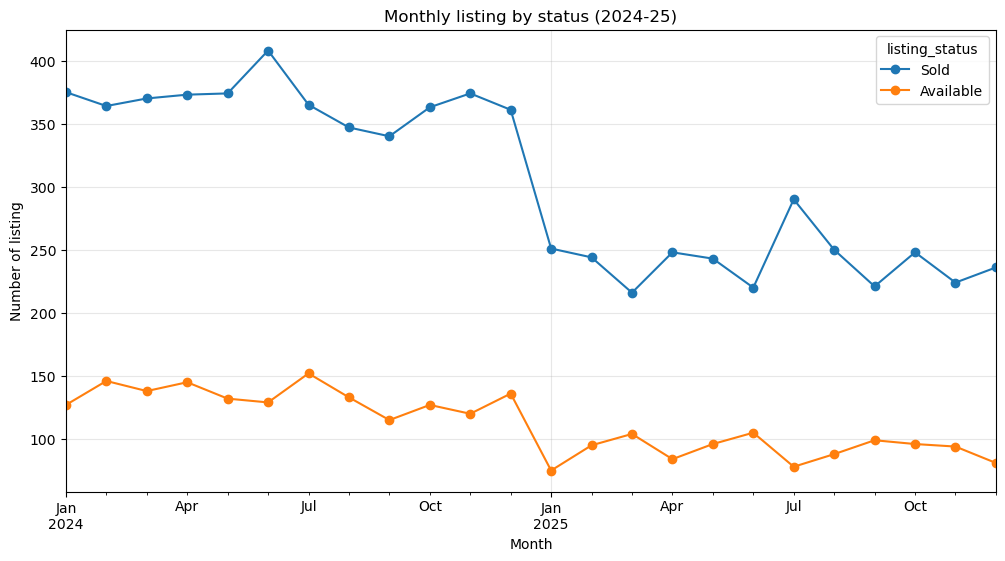

In [5]:
# Ḷine plot of Sold vs Available month
monthly[["Sold","Available"]].plot(figsize=(12,6),marker="o")
plt.title("Monthly listing by status (2024-25)")
plt.xlabel("Month")
plt.ylabel("Number of listing")
plt.grid(alpha=0.3)
plt.show()

In [6]:
# Adding a year column and then we will compare it with 2024 vs 2025 
props["year"] = props["transaction_date"].dt.year

counts = props.groupby(["year","listing_status"]).size().unstack()
print(counts)
print(pd.crosstab(props["year"], props["listing_status"], normalize="index").round(3))

listing_status  Available  Sold
year                           
2024                 1600  4414
2025                 1095  2891
listing_status  Available   Sold
year                            
2024                0.266  0.734
2025                0.275  0.725


In [7]:
# listings per tower 2024 vs 25 with % change
by_tower = props.groupby(["tower_number","year"]).size().unstack()
by_tower["change_%"] = ((by_tower[2025]/by_tower[2024]-1)*100).round()
print(by_tower)

# also we will do same for apartment vs office
by_cat = props.groupby(["unit_category","year"]).size().unstack()
by_cat["change_%"] = ((by_cat[2025]/by_cat[2024]-1)*100).round()
print(by_cat)

year          2024  2025  change_%
tower_number                      
1              276   200     -28.0
2              343   208     -39.0
3              332   242     -27.0
4              298   187     -37.0
5              296   206     -30.0
6              283   193     -32.0
7              315   205     -35.0
8              304   198     -35.0
9              326   211     -35.0
10             267   165     -38.0
11             349   214     -39.0
12             238   178     -25.0
13             359   247     -31.0
14             282   194     -31.0
15             312   208     -33.0
16             228   162     -29.0
17             279   171     -39.0
18             364   225     -38.0
19             271   162     -40.0
20             292   210     -28.0
year           2024  2025  change_%
unit_category                      
Apartment      5149  3398     -34.0
Office          865   588     -32.0


In [8]:
# only the sold listings counts as real sales and also (available pricing is the asking price) 
sold = props[props["listing_status"] == "Sold"].copy()
sold["price_per_sqft"] = sold["sale_price"] / sold["floor_area_sqft"]

In [9]:
# yearly average
print(sold.groupby("year")[["sale_price","price_per_sqft","floor_area_sqft"]].mean().round(1))

      sale_price  price_per_sqft  floor_area_sqft
year                                             
2024    344581.5           302.2           1140.7
2025    345820.9           302.8           1141.9


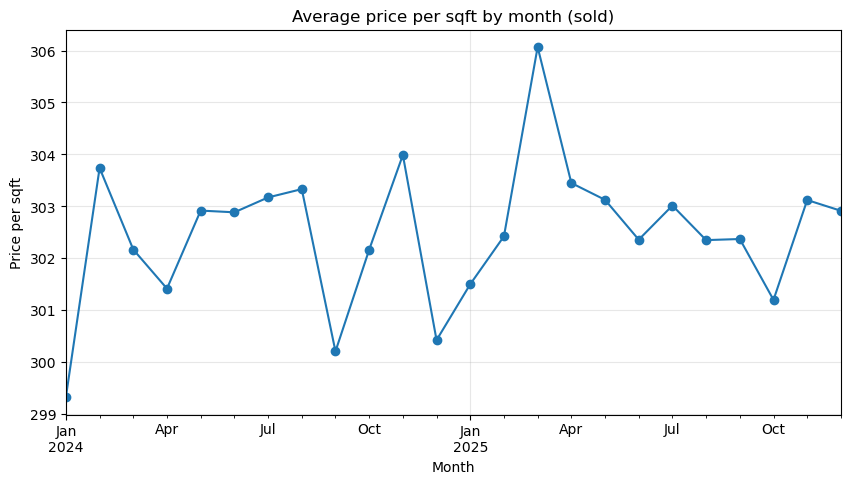

In [10]:
# avg price per sqft by month
monthly_price = sold.groupby("transaction_date")["price_per_sqft"].mean()

monthly_price.plot(figsize=(10,5), marker="o")
plt.title("Average price per sqft by month (sold)")
plt.xlabel("Month")
plt.ylabel("Price per sqft")
plt.grid(alpha=0.3)
plt.show()

In [11]:
# one row for one client and built from sold listings
client_agg = sold.groupby("client_ref").agg(
    n_purchase=("listing_id","count"),
    total_spend=("sale_price","sum"),
    avg_price=("sale_price","mean"),
    avg_area=("floor_area_sqft","mean"),
    avg_price_per_sqft=("price_per_sqft","mean"),
    pct_Office=("unit_category",lambda s: (s=="Office").mean()),
    first_purchase=("transaction_date","min"),
    last_purchase=("transaction_date","max"),   
).reset_index().rename(columns={"client_ref":"client_id"})
print(client_agg.shape)
client_agg.describe().round(1)

(2000, 9)


,n_purchase,total_spend,avg_price,avg_area,avg_price_per_sqft,pct_Office,first_purchase,last_purchase
count,2000.0,2000.0,2000.0,2000.0,2000.0,2000.0,2000,2000
mean,3.7,1260375.5,347090.0,1147.5,302.5,0.1,2024-04-27 07:39:21.600000,2025-06-01 11:18:14.400000
min,3.0,463612.0,154537.3,564.0,246.9,0.0,2024-01-01 00:00:00,2024-02-01 00:00:00
25%,3.0,1025238.0,295807.7,985.0,292.2,0.0,2024-02-01 00:00:00,2025-02-22 00:00:00
50%,4.0,1220893.2,341523.4,1129.2,302.3,0.0,2024-04-01 00:00:00,2025-07-01 00:00:00
75%,4.0,1441973.9,390843.3,1296.6,313.0,0.2,2024-07-01 00:00:00,2025-10-01 00:00:00
max,13.0,3653385.4,563423.5,1800.4,373.7,1.0,2025-09-01 00:00:00,2025-12-01 00:00:00
std,0.8,347830.7,69721.8,219.9,16.0,0.2,NaN,NaN


In [12]:
# we will join the purchase behaviour with client attributes
df = clients.merge(client_agg, on="client_id", how="left")
print(df.shape)
print(df["n_purchase"].isna().sum())
df.head()

(2000, 21)
0


,client_id,client_type,first_name,last_name,date_of_birth,gender,country,region,acquisition_purpose,satisfaction_score,...,referral_channel,is_company,n_purchase,total_spend,avg_price,avg_area,avg_price_per_sqft,pct_Office,first_purchase,last_purchase
0,C0001,Individual,Kareem,Liu,1968-05-11,F,USA,California,Home,4,...,Website,0,4,1246764.72,311691.180000,983.885000,319.963172,0.0,2024-10-01,2025-12-01
1,C0002,Individual,Trystan,Oconnor,1962-11-26,M,USA,California,Home,1,...,Website,0,5,1841095.93,368219.186000,1187.942000,313.167909,0.0,2024-01-01,2025-12-01
2,C0003,Individual,Kale,Gay,1959-04-07,M,USA,California,Home,4,...,Agency,0,5,1661457.59,332291.518000,1058.110000,310.797967,0.0,2024-07-01,2025-10-01
3,C0004,Individual,Russell,Gross,1959-11-25,M,USA,California,Home,5,...,Website,0,6,1608263.51,268043.918333,937.103333,275.564086,0.0,2024-02-01,2025-08-01
4,C0005,Company,Marleez,Co,1976-02-28,M,USA,California,Investment,5,...,Website,1,13,3653385.38,281029.644615,927.296154,299.398863,0.0,2024-02-01,2025-05-01


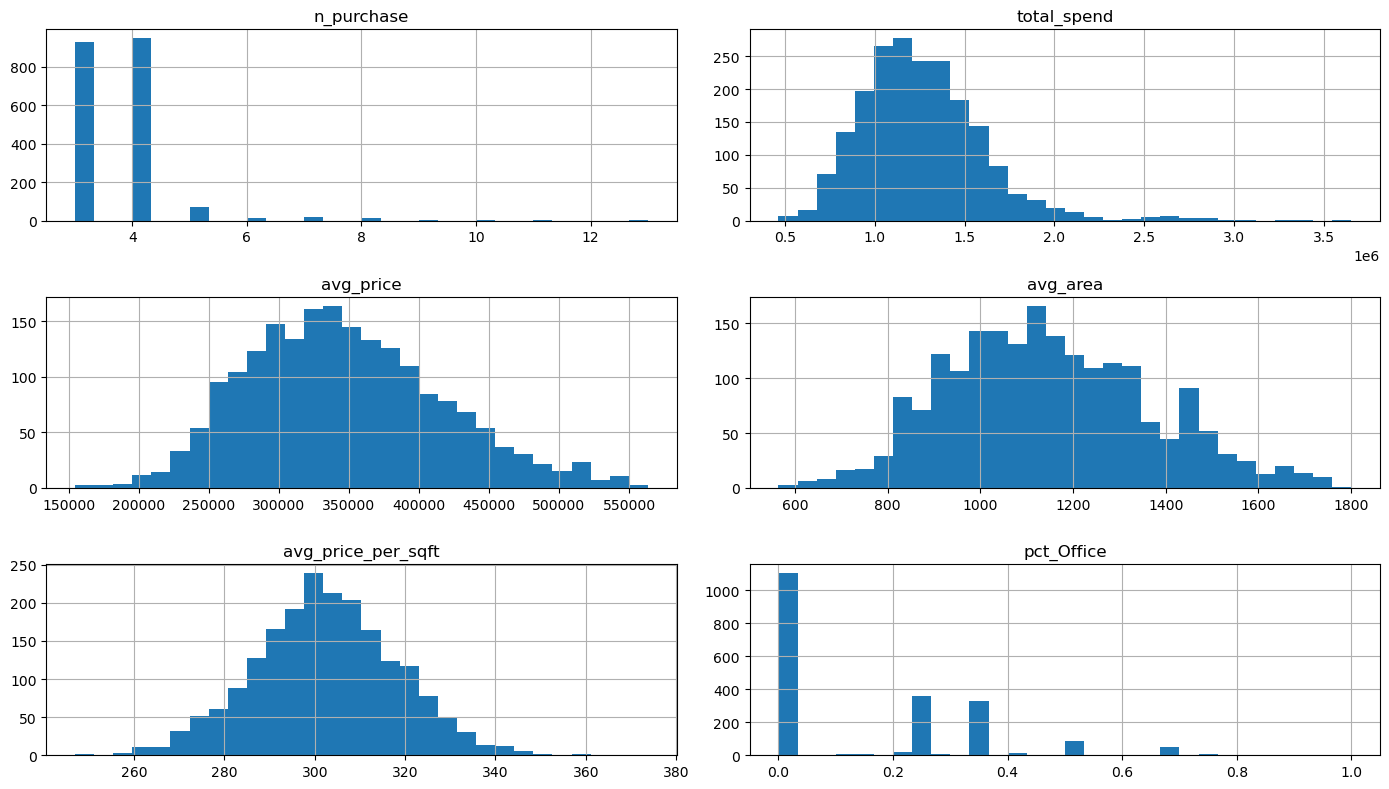

In [13]:
nums_col = ["n_purchase","total_spend","avg_price","avg_area","avg_price_per_sqft","pct_Office"]
df[nums_col].hist(bins=30,figsize=(14,8))
plt.tight_layout()
plt.show()

In [14]:
# clients with more than 8 purchase
heavy = df[df["n_purchase"]>=8]
print(len(heavy))
print(heavy[["client_id","client_type","country","acquisition_purpose",
             "n_purchase","total_spend"]].sort_values("n_purchase",ascending=False).head(15))

18
    client_id client_type  country acquisition_purpose  n_purchase  \
4       C0005     Company      USA          Investment          13   
6       C0007  Individual   Canada          Investment          11   
25      C0026  Individual      USA          Investment          10   
49      C0050  Individual      USA                Home           9   
101     C0102  Individual      USA          Investment           9   
160     C0161  Individual      USA                Home           9   
91      C0092  Individual      USA                Home           8   
115     C0116  Individual      USA          Investment           8   
116     C0117  Individual       UK          Investment           8   
45      C0046  Individual      USA                Home           8   
142     C0143  Individual      USA                Home           8   
172     C0173  Individual      USA                Home           8   
178     C0179  Individual      USA          Investment           8   
181     C0182  In

In [15]:
# is purchase pattern different by client type or purpose
print(df.groupby("client_type")[["n_purchase","total_spend","pct_Office"]].mean().round(2))
print(df.groupby("acquisition_purpose")[["n_purchase","total_spend","pct_Office"]].mean().round(2))

             n_purchase  total_spend  pct_Office
client_type                                     
Company            3.70   1263753.49        0.15
Individual         3.65   1260192.07        0.15
                     n_purchase  total_spend  pct_Office
acquisition_purpose                                     
Home                       3.65   1263587.55        0.15
Investment                 3.65   1253141.79        0.16


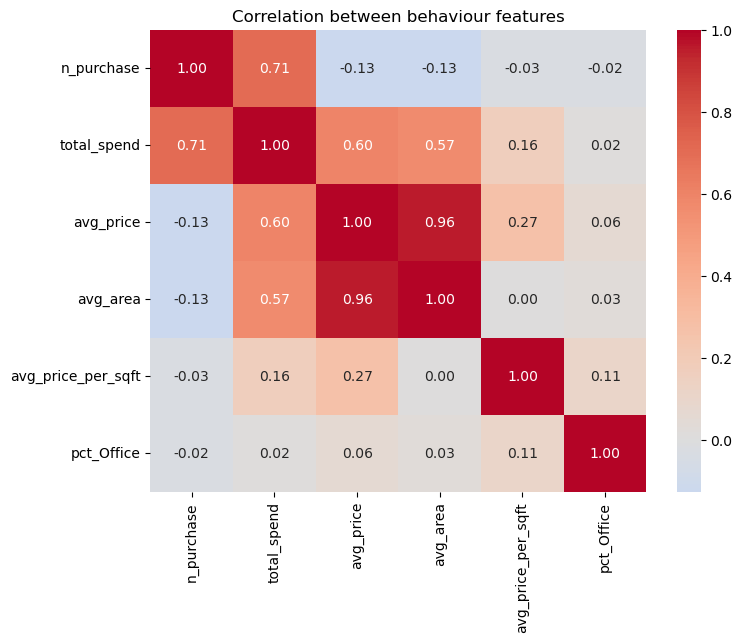

In [16]:
corr = df[nums_col].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation between behaviour features")
plt.show()

In [17]:
# clustering
cluster_features = ["n_purchase","avg_price","avg_price_per_sqft","pct_Office"]
profile_extra = ["total_spend","avg_area"]

print(df[cluster_features].corr().round(2))
print(df[cluster_features].describe().round(2))

                    n_purchase  avg_price  avg_price_per_sqft  pct_Office
n_purchase                1.00      -0.13               -0.03       -0.02
avg_price                -0.13       1.00                0.27        0.06
avg_price_per_sqft       -0.03       0.27                1.00        0.11
pct_Office               -0.02       0.06                0.11        1.00
       n_purchase  avg_price  avg_price_per_sqft  pct_Office
count     2000.00    2000.00             2000.00     2000.00
mean         3.65  347089.96              302.51        0.15
std          0.84   69721.82               15.97        0.18
min          3.00  154537.32              246.92        0.00
25%          3.00  295807.68              292.16        0.00
50%          4.00  341523.38              302.27        0.00
75%          4.00  390843.32              313.04        0.25
max         13.00  563423.50              373.74        1.00


In [18]:
# exclude company row for gender
feats = ["n_purchase","avg_price","avg_price_per_sqft","pct_Office"]
ind = df[df["is_company"]==0]

print("--- loan_applied ---")
print(df.groupby("loan_applied")[feats].mean().round(2))
print("\n--- referral_channel ---")
print(df.groupby("referral_channel")[feats].mean().round(2))
print("\n--- gender (individual only) ---")
print(ind.groupby("gender")[feats].mean().round(2))
print("\n--- satisfaction_score correlation ---")
print(df[feats + ["satisfaction_score"]].corr()["satisfaction_score"].round(2))

--- loan_applied ---
              n_purchase  avg_price  avg_price_per_sqft  pct_Office
loan_applied                                                       
No                  3.66  347198.43              302.49        0.15
Yes                 3.65  346903.66              302.54        0.15

--- referral_channel ---
                  n_purchase  avg_price  avg_price_per_sqft  pct_Office
referral_channel                                                       
Agency                  3.61  346005.00              301.68        0.15
Client                  3.63  343287.25              302.80        0.15
Website                 3.68  348445.36              302.99        0.15

--- gender (individual only) ---
        n_purchase  avg_price  avg_price_per_sqft  pct_Office
gender                                                       
F             3.62  344602.78              302.04        0.15
M             3.68  349817.09              303.08        0.15

--- satisfaction_score correlation ---

In [19]:
# age 
ref_date = pd.Timestamp("2025-12-31")

df["date_of_birth"] = pd.to_datetime(df["date_of_birth"])
df["age"] = (ref_date - df["date_of_birth"]).dt.days / 365.25

df.loc[df["is_company"]== 1,"age"] = np.nan
print(df["age"].describe().round(2))

count    1897.00
mean       56.03
std        17.54
min        25.03
25%        41.16
50%        56.73
75%        70.66
max        94.88
Name: age, dtype: float64


In [20]:
feats = ["n_purchase","avg_price","avg_price_per_sqft","pct_Office"]
print("--- correlation with age ---")
print(df[feats + ["age"]].corr()["age"].round(2))

df["age_band"] = pd.cut(df["age"], bins=[0,35,50,65,120],
                       labels=["<35","35-50","50-65","65+"])
print("\n--- behaviour by age band ---")
print(df.groupby("age_band", observed=True)[feats].mean().round(2))

--- correlation with age ---
n_purchase            0.09
avg_price            -0.01
avg_price_per_sqft   -0.01
pct_Office            0.02
age                   1.00
Name: age, dtype: float64

--- behaviour by age band ---
          n_purchase  avg_price  avg_price_per_sqft  pct_Office
age_band                                                       
<35             3.50  349468.60              301.65        0.13
35-50           3.60  347987.01              303.92        0.16
50-65           3.73  345795.04              302.40        0.15
65+             3.69  346736.83              302.29        0.15


In [21]:
df.to_csv("../data/processed/client_features.csv", index=False)